## #16 Momentum

In [1]:
import tensorflow as tf
# import tensorflow_datasets as tfds

import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
"""
    def load_dataset(dataset_name, split):
        ds, ds_info = tfds.load(dataset_name, split=split, shuffle_files=True, with_info=True, as_supervised=True)
        return ds, ds_info

    def shuffle_dataset(ds):
        buffer_size = tf.data.experimental.cardinality(ds).numpy()
        return ds.shuffle(buffer_size)

    def split_dataset(ds, train_ratio=0.9):
        num_examples = tf.data.experimental.cardinality(ds).numpy()
        num_train = int(train_ratio * num_examples)
        train_ds = ds.take(num_train)
        test_ds = ds.skip(num_train)
        return train_ds, test_ds

    def preprocess(image, label):
        image = tf.cast(image, tf.float32)
        image = (image / 127.5) - 1
        image = tf.image.resize(image, (224, 224))
        return image, label

    def prepare_dataset(ds, batch_size=32):
        return ds.map(preprocess).batch(batch_size)

    # Load the Caltech-101 dataset
    train_ds, ds_info = load_dataset('caltech101', 'train')
    test_ds, _ = load_dataset('caltech101', 'test')

    # Concatenate the train and test datasets
    all_ds = train_ds.concatenate(test_ds)

    # Shuffle the combined dataset
    all_ds = shuffle_dataset(all_ds)

    # Split the combined dataset into train and test datasets
    train_ds, test_ds = split_dataset(all_ds)

    # Prepare the datasets for training
    train_ds = prepare_dataset(train_ds)
    test_ds = prepare_dataset(test_ds)
"""

"\n    def load_dataset(dataset_name, split):\n        ds, ds_info = tfds.load(dataset_name, split=split, shuffle_files=True, with_info=True, as_supervised=True)\n        return ds, ds_info\n\n    def shuffle_dataset(ds):\n        buffer_size = tf.data.experimental.cardinality(ds).numpy()\n        return ds.shuffle(buffer_size)\n\n    def split_dataset(ds, train_ratio=0.9):\n        num_examples = tf.data.experimental.cardinality(ds).numpy()\n        num_train = int(train_ratio * num_examples)\n        train_ds = ds.take(num_train)\n        test_ds = ds.skip(num_train)\n        return train_ds, test_ds\n\n    def preprocess(image, label):\n        image = tf.cast(image, tf.float32)\n        image = (image / 127.5) - 1\n        image = tf.image.resize(image, (224, 224))\n        return image, label\n\n    def prepare_dataset(ds, batch_size=32):\n        return ds.map(preprocess).batch(batch_size)\n\n    # Load the Caltech-101 dataset\n    train_ds, ds_info = load_dataset('caltech101', '

In [ ]:
data_dir = r"D:/Learning/AI_MachineLearning/DeepLearning/Aghamohammadi/Original_Course\DLAghmohamadiCodes\caltech-101"\
            r"\caltech-101\101_ObjectCategories.tar\101_ObjectCategories"

def load_dataset_from_dir(data_dir, img_height=224, img_width=224, batch_size=32):
    # Load the entire dataset (train+val) without split
    ds = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        labels="inferred",
        label_mode="int",
        image_size=(img_height, img_width),
        batch_size=None,
        shuffle=True,
    )
    return ds

def shuffle_dataset(ds):
    buffer_size = tf.data.experimental.cardinality(ds).numpy()
    return ds.shuffle(buffer_size)

def split_dataset(ds, train_ratio=0.9):
    num_examples = tf.data.experimental.cardinality(ds).numpy()
    num_train = int(train_ratio * num_examples)
    train_ds = ds.take(num_train)
    test_ds = ds.skip(num_train)
    return train_ds, test_ds

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1
    image = tf.image.resize(image, (224, 224))
    return image, label

def prepare_dataset(ds, batch_size=32):
    return ds.map(preprocess).batch(batch_size)

# Load the raw dataset from the folder
all_ds = load_dataset_from_dir(data_dir)
# Shuffle the entire dataset
all_ds = shuffle_dataset(all_ds)
# Split into train and test
train_ds, test_ds = split_dataset(all_ds)
# Prepare datasets (preprocessing + batching)
train_ds = prepare_dataset(train_ds)
test_ds = prepare_dataset(test_ds)

Found 9144 files belonging to 102 classes.


In [6]:
num_classes = len(os.listdir(data_dir))

# Define the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.SGD(momentum=0.5, learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [7]:
# Train the model
model.fit(train_ds, epochs=20, validation_data=test_ds, batch_size=32)

Epoch 1/20
258/258 [==============================] - 87s 280ms/step - loss: 3.5238 - accuracy: 0.2925 - val_loss: 2.9013 - val_accuracy: 0.3792
Epoch 2/20
258/258 [==============================] - 65s 166ms/step - loss: 2.8368 - accuracy: 0.4055 - val_loss: 2.5011 - val_accuracy: 0.4459
Epoch 3/20
258/258 [==============================] - 49s 139ms/step - loss: 2.4534 - accuracy: 0.4658 - val_loss: 2.1815 - val_accuracy: 0.5224
Epoch 4/20
258/258 [==============================] - 49s 145ms/step - loss: 2.1580 - accuracy: 0.5264 - val_loss: 2.0730 - val_accuracy: 0.5257
Epoch 5/20
258/258 [==============================] - 57s 170ms/step - loss: 1.9161 - accuracy: 0.5753 - val_loss: 1.7697 - val_accuracy: 0.5858
Epoch 6/20
258/258 [==============================] - 52s 149ms/step - loss: 1.6748 - accuracy: 0.6305 - val_loss: 1.3824 - val_accuracy: 0.7257
Epoch 7/20
258/258 [==============================] - 53s 155ms/step - loss: 1.4738 - accuracy: 0.6810 - val_loss: 1.3495 - val_ac

In [8]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 150528)            0         
                                                                 
 dense_4 (Dense)             (None, 512)               77070848  
                                                                 
 dense_5 (Dense)             (None, 256)               131328    
                                                                 
 dense_6 (Dense)             (None, 128)               32896     
                                                                 
 dense_7 (Dense)             (None, 102)               13158     
                                                                 
Total params: 77,248,230
Trainable params: 77,248,230
Non-trainable params: 0
_________________________________________________________________


In [ ]:
"""
    def get_random_batches(test_ds, num_batches=4):
        return np.random.choice(len(test_ds), size=num_batches, replace=False)

    def get_random_image_and_labels(test_ds, batch):
        images, labels = list(test_ds)[batch]
        index = np.random.choice(len(images), size=1)[0]
        return images[index], labels[index]

    def predict_labels(model, images):
        y_probs_batch = model.predict(images)
        return np.argmax(y_probs_batch, axis=-1)

    def plot_image(ax, image, true_label, pred_label):
        ax.set_axis_off()
        image_to_show = (image + 1) / 2
        ax.imshow(image_to_show.numpy(), cmap=plt.cm.gray_r, interpolation='nearest')
        title = f'True: {true_label}, Pred: {pred_label}'
        ax.set_title(title, color='green' if true_label == pred_label else 'red')

    def plot_images(model, test_ds, class_names):
        batches = get_random_batches(test_ds)
        _, axes = plt.subplots(nrows=1, ncols=len(batches), figsize=(20, 6))
        for i, batch in enumerate(batches):
            image, true_label = get_random_image_and_labels(test_ds, batch)
            y_pred_batch = predict_labels(model, image[None, ...])
            pred_label = class_names[y_pred_batch[0]]
            true_label = class_names[true_label.numpy()]
            plot_image(axes[i], image, true_label, pred_label)
        plt.setp(axes, xticks=[], xticklabels=[], yticklabels=[])
        plt.tight_layout()
        plt.show()

    # Get the class names from ds_info
    class_names = ds_info.features['label'].names

    # Plot the images with the actual and predicted labels
    plot_images(model, test_ds, class_names)
"""

In [11]:
# convert once
test_ds_list = list(test_ds)

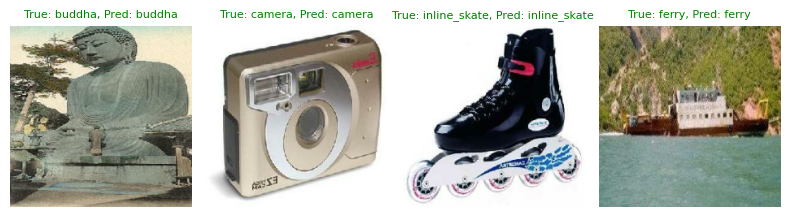

In [17]:
def get_random_batches(test_ds_list, num_batches=4):
    return np.random.choice(len(test_ds_list), size=num_batches, replace=False)

def get_random_image_and_labels(test_ds_list, batch):
    images, labels = test_ds_list[batch]
    index = np.random.choice(len(images), size=1)[0]
    return images[index], labels[index]

def predict_labels(model, image):
    y_probs_batch = model.predict(image[None, ...], verbose=0)
    return np.argmax(y_probs_batch, axis=-1)

def plot_image(ax, image, true_label, pred_label):
    ax.set_axis_off()
    image_to_show = (image + 1) / 2
    ax.imshow(image_to_show.numpy())
    title = f'True: {true_label}, Pred: {pred_label}'
    ax.set_title(title, fontsize=8, color='green' if true_label == pred_label else 'red')

def plot_images(model, test_ds_list, class_names):
    batches = get_random_batches(test_ds_list)
    _, axes = plt.subplots(nrows=1, ncols=len(batches), figsize=(8, 3))
    for i, batch in enumerate(batches):
        image, true_label = get_random_image_and_labels(test_ds_list, batch)
        pred_label_idx = predict_labels(model, image)[0]
        pred_label = class_names[pred_label_idx]
        true_label = class_names[true_label.numpy()]
        plot_image(axes[i], image, true_label, pred_label)
    plt.setp(axes, xticks=[], xticklabels=[], yticklabels=[])
    plt.tight_layout()
    plt.show()

# class names from directory
class_names = sorted(os.listdir(data_dir))

# usage
plot_images(model, test_ds_list, class_names)

## #17 Nesterov Accelerated Momentum

In [18]:
import tensorflow as tf
import os
import numpy as np
import matplotlib.pyplot as plt

In [19]:
data_dir = r"D:/Learning/AI_MachineLearning/DeepLearning/Aghamohammadi/Original_Course\DLAghmohamadiCodes\caltech-101"\
            r"\caltech-101\101_ObjectCategories.tar\101_ObjectCategories"

def load_dataset_from_dir(data_dir, img_height=224, img_width=224, batch_size=32):
    # Load the entire dataset (train+val) without split
    ds = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        labels="inferred",
        label_mode="int",
        image_size=(img_height, img_width),
        batch_size=None,
        shuffle=True,
    )
    return ds

def shuffle_dataset(ds):
    buffer_size = tf.data.experimental.cardinality(ds).numpy()
    return ds.shuffle(buffer_size)

def split_dataset(ds, train_ratio=0.9):
    num_examples = tf.data.experimental.cardinality(ds).numpy()
    num_train = int(train_ratio * num_examples)
    train_ds = ds.take(num_train)
    test_ds = ds.skip(num_train)
    return train_ds, test_ds

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1
    image = tf.image.resize(image, (224, 224))
    return image, label

def prepare_dataset(ds, batch_size=32):
    return ds.map(preprocess).batch(batch_size)

# Load the raw dataset from the folder
all_ds = load_dataset_from_dir(data_dir)
# Shuffle the entire dataset
all_ds = shuffle_dataset(all_ds)
# Split into train and test
train_ds, test_ds = split_dataset(all_ds)
# Prepare datasets (preprocessing + batching)
train_ds = prepare_dataset(train_ds)
test_ds = prepare_dataset(test_ds)

Found 9144 files belonging to 102 classes.


In [21]:
num_classes = len(os.listdir(data_dir))

# Define the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.SGD(momentum=0.5, learning_rate=0.001, nesterov=True),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [22]:
# Train the model
model.fit(train_ds, epochs=20, validation_data=test_ds, batch_size=32)

Epoch 1/20
258/258 [==============================] - 149s 363ms/step - loss: 3.6113 - accuracy: 0.2744 - val_loss: 3.1746 - val_accuracy: 0.3366
Epoch 2/20
258/258 [==============================] - 54s 166ms/step - loss: 2.9691 - accuracy: 0.3878 - val_loss: 2.6052 - val_accuracy: 0.4623
Epoch 3/20
258/258 [==============================] - 55s 170ms/step - loss: 2.6186 - accuracy: 0.4472 - val_loss: 2.3984 - val_accuracy: 0.5137
Epoch 4/20
258/258 [==============================] - 56s 172ms/step - loss: 2.3060 - accuracy: 0.5070 - val_loss: 2.0140 - val_accuracy: 0.5803
Epoch 5/20
258/258 [==============================] - 57s 172ms/step - loss: 2.0275 - accuracy: 0.5643 - val_loss: 1.8479 - val_accuracy: 0.6098
Epoch 6/20
258/258 [==============================] - 55s 167ms/step - loss: 1.8107 - accuracy: 0.6074 - val_loss: 1.7746 - val_accuracy: 0.6077
Epoch 7/20
258/258 [==============================] - 55s 169ms/step - loss: 1.5999 - accuracy: 0.6521 - val_loss: 1.3957 - val_a

## #19 Learning Rate Scheduler

In [1]:
# Import necessary libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
import tensorflow as tf

In [ ]:
# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

# Preprocess the data
scaler = MinMaxScaler(feature_range=(-1, 1))
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Define the SGD optimizer with the specified learning rate and momentum
sgd = SGD(learning_rate=0.3, momentum=0.9, nesterov=True)

# Compile the model using SGD as the optimizer
model.compile(optimizer=sgd, loss='binary_crossentropy', metrics=['accuracy'])

# Define the EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

# Define the ReduceLROnPlateau callback
reduce_lr = ReduceLROnPlateau(monitor='val_accuracy', factor=0.2, patience=5, min_lr=0.01)

# Add EarlyStopping to the callbacks list
callbacks = [early_stopping, reduce_lr]

# Train the model with the ReduceLROnPlateau and EarlyStopping callbacks
model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_test, y_test), callbacks=callbacks)

model.evaluate(X_test, y_test)

Epoch 1/100
16/16 [==============================] - 1s 29ms/step - loss: 0.3016 - accuracy: 0.8887 - val_loss: 0.1186 - val_accuracy: 0.9474 - lr: 0.3000
Epoch 2/100
16/16 [==============================] - 0s 14ms/step - loss: 0.1479 - accuracy: 0.9590 - val_loss: 0.1108 - val_accuracy: 0.9649 - lr: 0.3000
Epoch 3/100
16/16 [==============================] - 0s 17ms/step - loss: 0.1065 - accuracy: 0.9570 - val_loss: 0.0750 - val_accuracy: 0.9649 - lr: 0.3000
Epoch 4/100
16/16 [==============================] - 0s 15ms/step - loss: 0.0853 - accuracy: 0.9668 - val_loss: 0.0985 - val_accuracy: 0.9825 - lr: 0.3000
Epoch 5/100
16/16 [==============================] - 0s 17ms/step - loss: 0.0780 - accuracy: 0.9707 - val_loss: 0.0941 - val_accuracy: 0.9649 - lr: 0.3000
Epoch 6/100
16/16 [==============================] - 0s 13ms/step - loss: 0.1131 - accuracy: 0.9629 - val_loss: 0.0796 - val_accuracy: 0.9825 - lr: 0.3000
Epoch 7/100
16/16 [==============================] - 0s 15ms/step - lo

[0.098475381731987, 0.9824561476707458]